# Media effect

The Turnover + Refi model (notebook 06) badly underpredicts the 2001–03 refinance wave, even though those years are in
its training data. Incentive (loan rate − PMMS) cannot tell "1.5 pp in the money while rates hit 40-year lows and every
paper says *refinance now*" from "1.5 pp in the money in a quiet month". The **media effect**: when rates break to new
lows, coverage makes borrowers notice, and they refinance faster than incentive alone predicts.

Two ways to measure it, each added to the refinance part only (turnover is unchanged):

1. **PMMS media:** how far PMMS is below its lowest level of the previous 5 years, `max(0, min(PMMS, past 60 months) − PMMS)`.
   It measures the event that causes the coverage, not the coverage.
2. **NYT media:** articles per 10,000 New York Times articles that month about falling mortgage rates or refinancing
   (NYT Archive API, `source/nyt_media.py`). It measures the coverage itself, including coverage PMMS cannot see.

Both are lagged 1 month, like PMMS in the incentive. Three refinance models are compared: **Baseline** (notebook 06),
**+ PMMS media**, **+ NYT media**.

**Split:** as in notebook 06 (train 2000–2022, validate 2023, test 2024 on). 2001–03 is in training, so this measures
whether the feature lets the model *fit* the wave. The test years have no new lows, so test log loss should not move; the
checks are 2001–03 (target), 2009–13 and 2020–21 (other waves: does a feature fitted to 2003 overshoot them?) and the
test years (must not get worse).

In [1]:
# reload source/ modules when they change, no kernel restart needed
%load_ext autoreload
%autoreload 2

import re
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "source"))
from diagnostics import cpr, cpr_by
import nyt_media
from turnover_refi import load, fred, fit_turnover, fit_refi, score, REFI_FEATURES

# nyt_media.download()  # one request per month, about 70 minutes the first time; saved months are skipped

## 1. PMMS media

Monthly PMMS (lag 1). The feature is 0 unless PMMS is below every month of the previous 5 years, and grows with how far
below. The table shows how many months per year set a new 5-year low.

In [2]:
pmms = (fred("MORTGAGE30US").rename({"value": "pmms"})
          .with_columns(low_5y=pl.col("pmms").shift(1).rolling_min(60))
          .with_columns(media_pmms=(pl.col("low_5y") - pl.col("pmms")).clip(0)))

(pmms.filter(pl.col("t") >= 2000 * 12)
     .group_by(year=pl.col("t") // 12)
     .agg(pmms=pl.col("pmms").mean(), new_low_months=(pl.col("media_pmms") > 0).sum(), media_pmms=pl.col("media_pmms").mean(),
          max_media_pmms=pl.col("media_pmms").max())
     .sort("year"))

year,pmms,new_low_months,media_pmms,max_media_pmms
i32,f64,u32,f64,f64
2000,8.105792,0,0.0,0.0
2001,6.997458,1,0.007708,0.0925
2002,6.6215,4,0.045792,0.1975
2003,5.833833,6,0.069833,0.261
2004,5.848833,0,0.0,0.0
…,…,…,…,…
2022,5.055333,0,0.0,0.0
2023,6.757792,0,0.0,0.0
2024,6.732,0,0.0,0.0


## 2. NYT media

`nyt_media.download()` keeps every article whose headline, abstract or lead paragraph mentions mortgages, refinancing or
home loans, plus the month's total article count. Many of these are not about rates (Freddie Mac scandals, foreclosures,
housing columns), so an article counts as **rate-down news** only if it mentions mortgages *and* refinancing, a record
low, or rates falling.

In [3]:
MORTGAGE = r"mortgage|home loan"
RATES_DOWN = (r"refinanc|record low|lowest|"
              r"rates?\b.{0,60}\b(fell|fall|falls|falling|drop|drops|dropped|declin\w*|dip\w*|low)\b")

articles, totals = nyt_media.load()
text = pl.concat_str([pl.col("headline"), pl.col("abstract"), pl.col("lead_paragraph")], separator=" ", ignore_nulls=True)
articles = articles.with_columns(rates_down=text.str.contains(f"(?i){MORTGAGE}") & text.str.contains(f"(?i){RATES_DOWN}"))

news = (totals.join(articles.group_by("t").agg(mortgage=pl.len(), rates_down=pl.col("rates_down").sum()), on="t", how="left")
              .fill_null(0)
              .with_columns(media_nyt=10_000 * pl.col("rates_down") / pl.col("total"))
              .sort("t"))
print(f"{len(totals)} months downloaded, {len(articles):,} mortgage articles, {articles['rates_down'].sum():,} rate-down")

(news.group_by(year=pl.col("t") // 12)
     .agg(articles=pl.col("total").sum(), mortgage=pl.col("mortgage").sum(), rates_down=pl.col("rates_down").sum(),
          media_nyt=pl.col("media_nyt").mean())
     .sort("year"))

334 months downloaded, 8,247 mortgage articles, 614 rate-down


year,articles,mortgage,rates_down,media_nyt
i32,i64,u32,u32,f64
1999,96261,228,21,2.177187
2000,102800,184,12,1.162356
2001,111312,211,30,2.661028
2002,110050,252,51,4.636961
2003,108072,315,62,5.769615
…,…,…,…,…
2022,48707,71,7,1.373284
2023,46043,62,3,0.693106
2024,48696,77,16,3.299483


**Spot check.** Rate-down headlines in a wave (2003) and in a quiet, rising-rate year (2006). If 2006 is full of
unrelated stories, tighten `RATES_DOWN`.

In [4]:
pl.Config.set_fmt_str_lengths(110)
for year in [2003, 2006]:
    sample = articles.filter(pl.col("rates_down") & (pl.col("t") // 12 == year))
    print(year, len(sample), "rate-down articles")
    print(sample.select(pl.col("pub_date").str.slice(0, 10), "headline").sample(min(12, len(sample)), seed=0).sort("pub_date"))

2003 62 rate-down articles
shape: (12, 2)
┌────────────┬────────────────────────────────────────────────────────────────────────────┐
│ pub_date   ┆ headline                                                                   │
│ ---        ┆ ---                                                                        │
│ str        ┆ str                                                                        │
╞════════════╪════════════════════════════════════════════════════════════════════════════╡
│ 2003-01-16 ┆ Mortgage Index Declines                                                    │
│ 2003-01-16 ┆ Guess Who's Coming for a Mortgage?                                         │
│ 2003-03-08 ┆ Rates Keep Sliding Toward the 1950's                                       │
│ 2003-04-06 ┆ In the Region/New Jersey; Refinancing Fever Also Strikes Commercial Owners │
│ 2003-04-17 ┆ Mild Weather and Low Rates Bring Surge in Home Building                    │
│ …          ┆ …                      

**Both media series against the refinance wave.** Refinance CPR is the notebook 06 split: actual SMM minus
modeled turnover, per month. Media series are shown in the month they enter the model (after the 1-month lag).

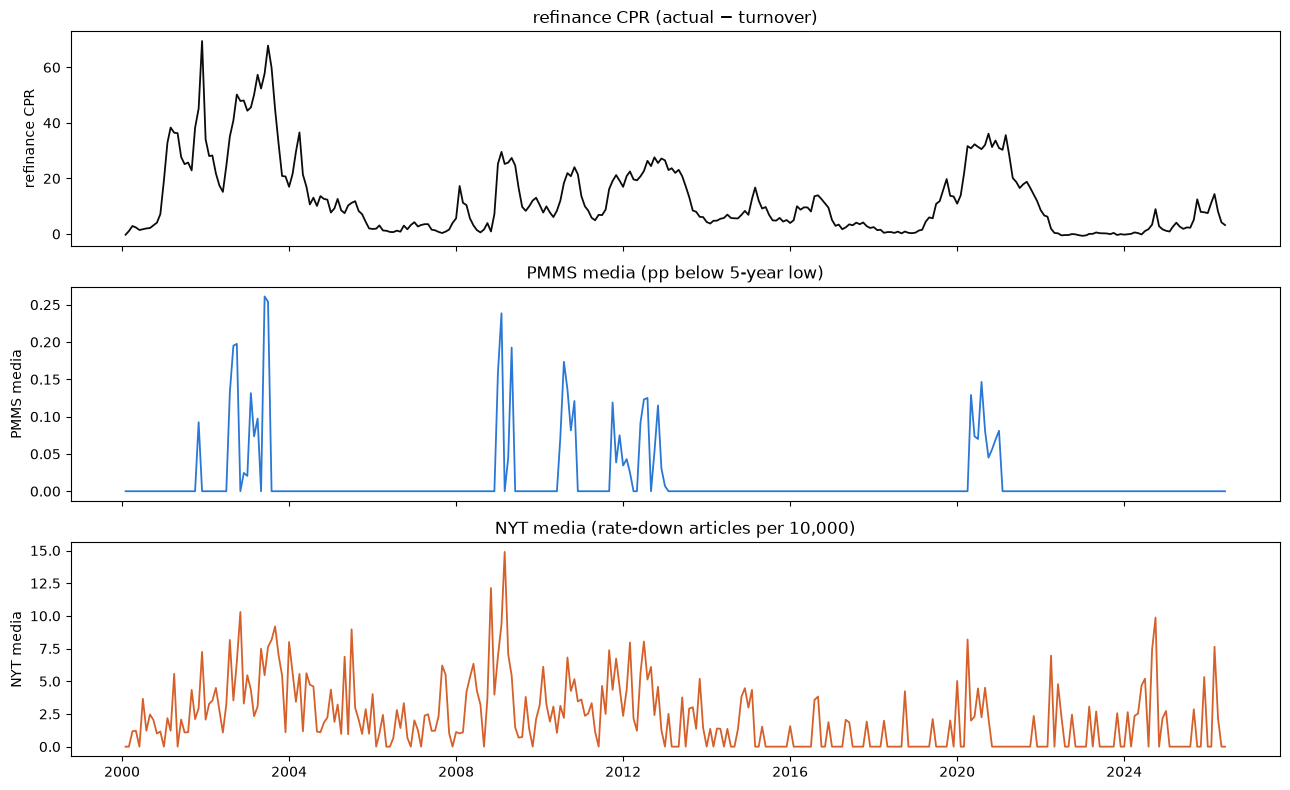

corr refi vs PMMS media,corr refi vs NYT media,corr PMMS vs NYT media
f64,f64,f64
0.531969,0.41272,0.331347


In [5]:
df = load()
data = {s: df.filter(pl.col("split") == s) for s in ["train", "valid", "test"]}
turn_model, data = fit_turnover(data)

w = pl.col("exposure")
avg = lambda c: (pl.col(c) * w).sum() / w.sum()
refi_by_month = (pl.concat(data.values()).group_by("t").agg(smm=avg("prepay"), turn=avg("turn"))
                   .with_columns(refi_cpr=cpr(pl.col("smm") - pl.col("turn"))))
nyt_feature = news.select(pl.col("t") + 1, "media_nyt")  # lag 1: articles in month m enter month m + 1
series = (refi_by_month.join(pmms.select("t", "media_pmms"), on="t", how="left").join(nyt_feature, on="t", how="left")
                       .with_columns(date=pl.date(pl.col("t") // 12, pl.col("t") % 12 + 1, 1)).sort("t"))

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, col, label, color in zip(axes, ["refi_cpr", "media_pmms", "media_nyt"],
                                 ["refinance CPR (actual − turnover)", "PMMS media (pp below 5-year low)",
                                  "NYT media (rate-down articles per 10,000)"], ["#0b0b0b", "#2a78d6", "#d6602a"]):
    ax.plot(series["date"], series[col], color=color, lw=1.3)
    ax.set(ylabel=label.split(" (")[0], title=label)
fig.tight_layout()
plt.show()

series.select(pl.corr("refi_cpr", "media_pmms").alias("corr refi vs PMMS media"),
              pl.corr("refi_cpr", "media_nyt").alias("corr refi vs NYT media"),
              pl.corr("media_pmms", "media_nyt").alias("corr PMMS vs NYT media"))

## 3. Three refinance models

Same turnover model, same split, same settings; only the refinance features change.

In [6]:
for s in data:
    data[s] = (data[s].join(pmms.select("t", "media_pmms"), on="t", how="left")
                      .join(nyt_feature, on="t", how="left"))

variants = {"Baseline": REFI_FEATURES,
            "+ PMMS media": REFI_FEATURES + ["media_pmms"],
            "+ NYT media": REFI_FEATURES + ["media_nyt"]}
refi = {name: fit_refi(features, data) for name, features in variants.items()}
P = {s: {name: d["turn"].to_numpy() + refi_p(d) for name, (_, refi_p) in refi.items()} for s, d in data.items()}

pl.DataFrame([{"split": s, "rounds": refi[name][0].best_iteration,
               **score(name, data[s]["prepay"].to_numpy(), P[s][name], data[s]["exposure"].to_numpy())}
              for s in ["valid", "test"] for name in variants])

split,rounds,model,log_loss,auc,actual_cpr,predicted_cpr
str,i64,str,f64,f64,f64,f64
"""valid""",138,"""Baseline""",0.027659,0.622809,4.038812,4.394318
"""valid""",124,"""+ PMMS media""",0.027656,0.622553,4.038812,4.388512
"""valid""",130,"""+ NYT media""",0.027653,0.622599,4.038812,4.373567
"""test""",138,"""Baseline""",0.04119,0.710333,9.207873,11.855004
"""test""",124,"""+ PMMS media""",0.041097,0.710269,9.207873,11.476557
"""test""",130,"""+ NYT media""",0.041977,0.708229,9.207873,13.34986


## 4. Does it catch the waves?

Actual vs. predicted CPR per year. The summary below averages the absolute miss (CPR points) over each episode.

In [7]:
everything = pl.concat(data.values())
by_year = cpr_by(everything, "year", {n: np.concatenate([P[s][n] for s in data]) for n in variants}, min_rows=1)
pl.Config.set_tbl_rows(30)
by_year.select("year", "actual", *variants)

year,actual,Baseline,+ PMMS media,+ NYT media
i32,f64,f64,f64,f64
2000,6.242991,8.720779,8.363642,6.786122
2001,40.057936,32.474031,32.105048,37.152216
2002,38.67216,27.234785,30.596695,35.36368
2003,53.482371,32.681673,43.752105,48.078362
2004,25.216944,18.113417,17.330564,20.547458
2005,16.121581,14.07824,13.760154,14.772727
2006,8.848365,8.813419,8.711109,8.700695
2007,8.573667,9.302989,9.142525,8.941312
2008,9.993928,9.980633,9.728325,10.30297


In [8]:
EPISODES = {"2001–03 wave": (2001, 2003), "2009–13 waves": (2009, 2013), "2020–21 wave": (2020, 2021),
            "quiet train years": None, "test 2024 on": (2024, 2100)}
QUIET = [2000, 2004, 2005, 2006, 2007, 2008, 2014, 2015, 2016, 2017, 2018, 2019, 2022]

def years(span):
    return pl.col("year").is_in(QUIET) if span is None else pl.col("year").is_between(*span)

pl.DataFrame([{"episode": name,
               **{n: by_year.filter(years(span)).select((pl.col(n) - pl.col("actual")).abs().mean()).item() for n in variants},
               **{f"bias {n}": by_year.filter(years(span)).select((pl.col(n) - pl.col("actual")).mean()).item()
                  for n in variants}}
              for name, span in EPISODES.items()])

episode,Baseline,+ PMMS media,+ NYT media,bias Baseline,bias + PMMS media,bias + NYT media
str,f64,f64,f64,f64,f64,f64
"""2001–03 wave""",13.273993,8.586206,3.872736,-13.273993,-8.586206,-3.872736
"""2009–13 waves""",2.929795,2.542518,1.695634,2.801857,2.175002,1.529241
"""2020–21 wave""",2.248981,1.680649,1.855218,-2.248981,-1.680649,-1.855218
"""quiet train years""",2.347675,2.097045,1.471413,0.933043,0.458481,0.522796
"""test 2024 on""",2.969763,2.589464,4.934522,2.969763,2.589464,4.934522


**How much the refinance part uses each media feature** (share of total split gain).

In [9]:
pl.DataFrame([{"model": name, "feature": f, "gain_pct": 100 * g / model.feature_importance("gain").sum()}
              for name, (model, _) in refi.items() if name != "Baseline"
              for f, g in zip(model.feature_name(), model.feature_importance("gain")) if f.startswith("media")])

model,feature,gain_pct
str,str,f64
"""+ PMMS media""","""media_pmms""",9.797877
"""+ NYT media""","""media_nyt""",14.838444


## 5. Better media features

Section 4 results: **PMMS media** cut the 2001–03 miss from 13.3 to 8.6 CPR and improved the test years; **NYT media**
cut it to 3.9 but blew up the test years (log loss 0.041977 vs. 0.041190), because NYT mortgage coverage collapses after
about 2015 and the feature became an era marker. This section tries fixes for both:

**PMMS** (all lag 1, like the incentive):
- `rate_drop_12m`: PMMS a year ago − PMMS now (pp). 2001 was not a 5-year low (1998 was as low), but rates had fallen
  about 1.5 pp in a year.
- `media_pmms_36`: like `media_pmms` but against the lowest rate of the previous 3 years instead of 5.
- `media_pmms_memory`: `media_pmms` with a fading memory (each month keeps 70% of last month's value, so about a 2-month
  half-life). Coverage peaks at the record; awareness lingers.

**NYT** (lag 1):
- `nyt_tone`: rate-down articles ÷ mortgage articles, over the last 3 months (single months have few articles). The
  post-2015 drop in coverage hits both counts, so the ratio is comparable across eras.
- `nyt_zscore`: `media_nyt` relative to its own previous 5 years, `(x − mean) / std`. A spike means "unusual for this
  period", not "high in absolute terms". NYT data starts in 1999, so early months use as little as 12 months of history
  (2001–03 would otherwise have no value).

Each is added on its own to the Baseline refinance features. Then the best PMMS and best NYT versions are combined.
**Best** = smallest 2001–03 miss among versions whose test log loss is no worse than `+ PMMS media` (0.041097).

In [10]:
DECAY = 0.7  # share of last month's media_pmms_memory kept

def fading(x, keep):
    out, carry = np.empty(len(x)), 0.0
    for i, v in enumerate(x):
        carry = v + keep * carry
        out[i] = carry
    return out

pmms = pmms.with_columns(rate_drop_12m=pl.col("pmms").shift(12) - pl.col("pmms"),
                         media_pmms_36=(pl.col("pmms").shift(1).rolling_min(36) - pl.col("pmms")).clip(0))
pmms = pmms.with_columns(media_pmms_memory=pl.Series(fading(pmms["media_pmms"].fill_null(0).to_numpy(), DECAY)))

news = news.with_columns(nyt_tone=pl.col("rates_down").rolling_sum(3) / pl.col("mortgage").rolling_sum(3),
                         nyt_zscore=(pl.col("media_nyt") - pl.col("media_nyt").shift(1).rolling_mean(60, min_samples=12))
                                    / pl.col("media_nyt").shift(1).rolling_std(60, min_samples=12))

PMMS_NEW = ["rate_drop_12m", "media_pmms_36", "media_pmms_memory"]
NYT_NEW = ["nyt_tone", "nyt_zscore"]
features = pmms.select("t", *PMMS_NEW).join(news.select(pl.col("t") + 1, *NYT_NEW), on="t", how="left")  # NYT lag 1
for s in data:
    data[s] = data[s].join(features, on="t", how="left", maintain_order="left")  # rows stay aligned with `everything`

(features.filter(pl.col("t") >= 2000 * 12)
         .group_by(year=pl.col("t") // 12).agg(pl.col(c).mean() for c in PMMS_NEW + NYT_NEW)
         .sort("year"))

year,rate_drop_12m,media_pmms_36,media_pmms_memory,nyt_tone,nyt_zscore
i32,f64,f64,f64,f64,f64
2000,-0.775125,0.0,0.000168,0.080209,-0.428412
2001,1.108333,0.007708,0.013106,0.108519,0.542963
2002,0.375958,0.045792,0.122282,0.202007,1.232025
2003,0.787667,0.069833,0.258388,0.208706,1.170298
2004,-0.015,0.0,0.017097,0.150062,0.134433
2005,0.027292,0.0,0.000237,0.138442,-0.232677
2006,-0.600708,0.0,0.000003,0.058641,-0.949278
2007,0.078458,0.0,4.5336e-8,0.032034,-0.505054
2008,0.24025,0.0,6.2751e-10,0.02921,0.402454


**Fit one refinance model per new feature.** Predictions are kept as float32 to save memory (one array per model
over all 40M loan-months).

In [11]:
def add_model(name, features):
    variants[name] = features
    refi[name] = fit_refi(features, data)
    for s, d in data.items():
        P[s][name] = (d["turn"].to_numpy() + refi[name][1](d)).astype(np.float32)

for f in PMMS_NEW + NYT_NEW:
    add_model(f"+ {f}", REFI_FEATURES + [f])

def results(names):
    """Average absolute miss (CPR) per episode and test log loss, one row per model."""
    by_year = cpr_by(everything, "year", {n: np.concatenate([P[s][n] for s in data]) for n in names}, min_rows=1)
    y, w = data["test"]["prepay"].to_numpy(), data["test"]["exposure"].to_numpy()
    return pl.DataFrame([{"model": n, "refi features": ", ".join(variants[n][len(REFI_FEATURES):]) or "-",
                          **{e: by_year.filter(years(span)).select((pl.col(n) - pl.col("actual")).abs().mean()).item()
                             for e, span in EPISODES.items()},
                          "2001–03 bias": by_year.filter(years((2001, 2003))).select((pl.col(n) - pl.col("actual")).mean()).item(),
                          "test log loss": score(n, y, P["test"][n], w)["log_loss"]}
                         for n in names])

table = results(list(variants))
table

model,refi features,2001–03 wave,2009–13 waves,2020–21 wave,quiet train years,test 2024 on,2001–03 bias,test log loss
str,str,f64,f64,f64,f64,f64,f64,f64
"""Baseline""","""-""",13.273993,2.929795,2.248981,2.347675,2.969763,-13.273993,0.04119
"""+ PMMS media""","""media_pmms""",8.586206,2.542518,1.680649,2.097045,2.589464,-8.586206,0.041097
"""+ NYT media""","""media_nyt""",3.872736,1.695634,1.855218,1.471413,4.934522,-3.872736,0.041977
"""+ rate_drop_12m""","""rate_drop_12m""",7.197,2.128883,2.044994,1.76158,2.497223,-7.197,0.041211
"""+ media_pmms_36""","""media_pmms_36""",8.540943,2.4803,1.487474,2.066508,3.171736,-8.540943,0.041237
"""+ media_pmms_memory""","""media_pmms_memory""",3.334201,1.9745,0.616257,1.184326,1.144789,-3.334201,0.040969
"""+ nyt_tone""","""nyt_tone""",4.042756,1.288685,1.236976,1.357587,3.476371,-4.042756,0.041506
"""+ nyt_zscore""","""nyt_zscore""",4.127287,1.320539,0.310329,1.334063,5.050421,-4.127287,0.042466


**Combine the best PMMS and best NYT versions.** If no NYT version passes the test-year rule, the combination is
skipped: NYT then adds nothing usable beyond rates.

In [12]:
LIMIT = table.filter(pl.col("model") == "+ PMMS media")["test log loss"].item()

def best(names):
    ok = table.filter(pl.col("model").is_in(names) & (pl.col("test log loss") <= LIMIT)).sort("2001–03 wave")
    return ok["model"][0] if len(ok) else None

best_pmms = best(["+ PMMS media"] + [f"+ {f}" for f in PMMS_NEW])
best_nyt = best(["+ NYT media"] + [f"+ {f}" for f in NYT_NEW])
print("best PMMS:", best_pmms, "| best NYT:", best_nyt)

if best_nyt is not None:
    add_model("best PMMS + best NYT", REFI_FEATURES + variants[best_pmms][len(REFI_FEATURES):]
              + variants[best_nyt][len(REFI_FEATURES):])
    table = results(list(variants))

pl.Config.set_tbl_cols(12)
table.sort("2001–03 wave")

best PMMS: + media_pmms_memory | best NYT: None


model,refi features,2001–03 wave,2009–13 waves,2020–21 wave,quiet train years,test 2024 on,2001–03 bias,test log loss
str,str,f64,f64,f64,f64,f64,f64,f64
"""+ media_pmms_memory""","""media_pmms_memory""",3.334201,1.9745,0.616257,1.184326,1.144789,-3.334201,0.040969
"""+ NYT media""","""media_nyt""",3.872736,1.695634,1.855218,1.471413,4.934522,-3.872736,0.041977
"""+ nyt_tone""","""nyt_tone""",4.042756,1.288685,1.236976,1.357587,3.476371,-4.042756,0.041506
"""+ nyt_zscore""","""nyt_zscore""",4.127287,1.320539,0.310329,1.334063,5.050421,-4.127287,0.042466
"""+ rate_drop_12m""","""rate_drop_12m""",7.197,2.128883,2.044994,1.76158,2.497223,-7.197,0.041211
"""+ media_pmms_36""","""media_pmms_36""",8.540943,2.4803,1.487474,2.066508,3.171736,-8.540943,0.041237
"""+ PMMS media""","""media_pmms""",8.586206,2.542518,1.680649,2.097045,2.589464,-8.586206,0.041097
"""Baseline""","""-""",13.273993,2.929795,2.248981,2.347675,2.969763,-13.273993,0.04119


**Year by year** for Baseline, the section 4 PMMS model, and the winners.

In [13]:
show = list(dict.fromkeys(["Baseline", "+ PMMS media", best_pmms, best_nyt, "best PMMS + best NYT"]))
show = [n for n in show if n in variants]
cpr_by(everything, "year", {n: np.concatenate([P[s][n] for s in data]) for n in show}, min_rows=1).select("year", "actual", *show)

year,actual,Baseline,+ PMMS media,+ media_pmms_memory
i32,f64,f64,f64,f64
2000,6.242991,8.720779,8.363642,6.949876
2001,40.057936,32.474031,32.105048,38.031969
2002,38.67216,27.234785,30.596695,34.467068
2003,53.482371,32.681673,43.752105,49.710828
2004,25.216944,18.113417,17.330564,20.745925
2005,16.121581,14.07824,13.760154,13.136021
2006,8.848365,8.813419,8.711109,8.743909
2007,8.573667,9.302989,9.142525,8.73478
2008,9.993928,9.980633,9.728325,9.581472


**Best model vs. actual CPR, monthly.** Shaded: validation (2023) and test (2024 on) years, which the model did not train on.

In [ ]:
from diagnostics import plot_over_time

plot_over_time(everything, {"Best model": np.concatenate([P[s][best_pmms] for s in data])},
               held_out=[(2023, 2024, "valid"), (2024, 2027, "test")])

## 6. Takeaways

Split: train 2000–2022, validate 2023, test 2024 on (as in notebook 06).

**Sections 1–4 (first run):**
- **PMMS media works.** 2001–03 miss 13.3 → 8.6 CPR (2003: 32.7 → 43.8 predicted vs. 53.5 actual), 2020–21 2.2 → 1.7,
  and the test years improve too: log loss 0.041190 → 0.041097, miss 3.0 → 2.6 CPR. 9.8% of the refinance model's gain.
- **2001 is not caught by PMMS media** (32.1 vs. 40.1 actual): rates were not below their 5-year low because 1998 was
  about as low.
- **NYT media fits the past but fails the test years.** 2001–03 miss 3.9 CPR and better 2009–13 and quiet years, but test
  log loss 0.041977 and test miss 4.9 CPR (2026: 22.1 predicted vs. 13.5 actual). NYT mortgage coverage collapses after
  about 2015, so the feature acts as an era marker (low in the overpredicted 2015–19 years), and the 2024 coverage spike
  then predicts a wave that did not come.

**Section 5 (better media features):** *to fill in after the run.*